<a href="https://colab.research.google.com/github/San-Maansson/Stock_Analysis/blob/main/mean_variance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
"""
Mean-variance
Generated log returns
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

    Asset_1   Asset_2   Asset_3   Asset_4   Asset_5  p_return
0 -0.165515  0.311192 -0.034197  0.008128 -0.423192 -0.060717
1  0.723973  0.171267  0.045457 -0.568225 -0.729578 -0.071421
2  0.663499 -0.588132  4.793548  0.720995  0.636262  1.245234
3  0.249811  0.527362  0.147206  1.281008  2.412954  0.923668
4  1.621613 -0.420254 -0.365273  0.045200  0.631566  0.302570


/tmp/ipykernel_1081/2976966628.py:74: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([df['Asset_1'], df['p_return']], labels=['Single asset', 'Portfolio'])


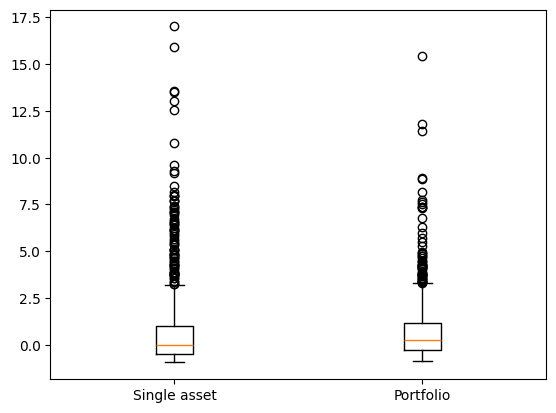

In [ ]:
def gen_log_normal_returns(n_obs = 1000, n_assets = 5, mean = None, cov=  None, rho = 0.5, seed = None):
    """
    Generate time series of correlated log-normal returns.
    Parameters
    ----------
    n_obs : int
        Number of time periods (rows).
    n_assets : int, number of securities.
    mean : array-like, shape (n_assets,), mean vector.
    cov : array-like, shape (n_assets, n_assets), optional
        , covariance matrix.
    rho : float
        Pairwise correlation coefficient used if cov is not supplied.
    seed : int, optional
        Random seed for reproducibility.

    Returns
    -------
    DataFrame
        Simulated log-normal returns with shape (n_obs, n_assets).
    """
    rng = np.random.default_rng(seed)

    # Default mean = zero vector
    if mean is None:
        mean = np.zeros(n_assets)

    #Default covariance: equicorrelation structure
    if cov is None:
        cov = np.full((n_assets, n_assets), rho)
        np.fill_diagonal(cov, 1.0)

    #Draw from multivariate normal
    mvn_draws = rng.multivariate_normal(mean, cov, size = n_obs)

    #Exponentiate to get log-normal returns
    returns = np.exp(mvn_draws) - 1

    return pd.DataFrame(returns, columns=[f"Asset_{i+1}" for i in range(n_assets)])

def portfolio_return(df, n_assets = 5, weights = None):
    """
    Parameters
    ----------
    df:         DataFrame with returns of assets.
    n_assets:   int, number of securities.
    weights:    array-like, shape (n_assets,), equal weights
                if not provided.
    Returns
    ----------
    p_return:   Series of portfolio returns
    """
    #Default is equal weighting
    if weights == None:
        weights = np.ones(n_assets)/n_assets

    #Portfolio return
    df['p_return'] = df.dot(weights)
    return weights


#Implementation
if __name__ == "__main__":
    df = gen_log_normal_returns(rho = 0.5, seed = 0)

    #Create portfolio
    portfolio_return(df)

    #Check data strcuture
    print(df.head())

    #Compare single investment and portfolio
    fig, ax = plt.subplots()
    ax.boxplot([df['Asset_1'], df['p_return']], labels=['Single asset', 'Portfolio'])
    plt.savefig('Figure14.png')
    plt.show()